# Análisis de actividad pesquera aparente en Shiretoko, Japón (2020–2024)

## Objetivo
Explorar la distribución temporal y espacial de los registros de esfuerzo pesquero aparente reportados por Global Fishing Watch (GFW) para las áreas EBSA 10401 y 10402 de Shiretoko. Este notebook utiliza la base consolidada previamente descargada; **no vuelve a consultar la API de GFW**.

## Productos
1. Revisión y limpieza básica de la base consolidada.
2. Resumen de registros y horas por año.
3. Distribución mensual e interanual.
4. Mapa de puntos y mapa de concentración espacial.
5. **Mapa de calor mensual:** número de registros por mes y año.
6. Exportación de tablas resumidas.

> **Interpretación:** los registros y las horas son indicadores de esfuerzo pesquero aparente derivados de datos AIS/GFW. No equivalen necesariamente a viajes, lances, capturas ni al esfuerzo total de la flota. La resolución consultada fue LOW y MONTHLY. Una coincidencia con clorofila-a no demostraría causalidad.

## 1. Bibliotecas y configuración

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

print("Bibliotecas cargadas.")

Bibliotecas cargadas.


## 2. Rutas de los archivos

Se espera que el notebook esté guardado en la carpeta `notebooks/` del repositorio y que el CSV consolidado esté en `datos/`. El GeoJSON de las áreas EBSA debe estar en la raíz del repositorio o en `notebooks/`.

In [2]:
DIRECTORIO = Path.cwd()
RUTA_BASE = DIRECTORIO.parent / "datos" / "GFW_Shiretoko_2020_2024.csv"

# Buscar el GeoJSON en las dos ubicaciones habituales
candidatos_geojson = [
    DIRECTORIO.parent / "Shiretoko_EBSA_10401_10402.geojson",
    DIRECTORIO / "Shiretoko_EBSA_10401_10402.geojson"
]
RUTA_GEOJSON = next((p for p in candidatos_geojson if p.exists()), None)

print("Directorio del notebook:", DIRECTORIO)
print("CSV:", RUTA_BASE, "| Existe:", RUTA_BASE.exists())
print("GeoJSON:", RUTA_GEOJSON)

Directorio del notebook: /home/jovyan/tutoriales/17-martes/ohwe26-proy2-python/datos
CSV: /home/jovyan/tutoriales/17-martes/ohwe26-proy2-python/datos/GFW_Shiretoko_2020_2024.csv | Existe: True
GeoJSON: /home/jovyan/tutoriales/17-martes/ohwe26-proy2-python/Shiretoko_EBSA_10401_10402.geojson


## 3. Carga de la base consolidada

In [3]:
if not RUTA_BASE.exists():
    raise FileNotFoundError(
        "No se encontró el CSV. Coloca GFW_Shiretoko_2020_2024.csv "
        "en la carpeta datos/ del repositorio."
    )

df = pd.read_csv(RUTA_BASE)
print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())
display(df.head())

Dimensiones: (67, 21)
Columnas: ['date', 'detections', 'flag', 'gear_type', 'hours', 'vessel_ids', 'vessel_id', 'vessel_type', 'entry_timestamp', 'exit_timestamp', 'first_transmission_date', 'last_transmission_date', 'imo', 'mmsi', 'call_sign', 'dataset', 'report_dataset', 'ship_name', 'lat', 'lon', 'year']


,date,detections,flag,gear_type,hours,vessel_ids,vessel_id,vessel_type,entry_timestamp,exit_timestamp,first_transmission_date,last_transmission_date,imo,mmsi,call_sign,dataset,report_dataset,ship_name,lat,lon,year
0,2020-09,NaN,NaN,NaN,20.724167,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,public-global-fishing-effort:v5.0,NaN,44.1,145.3,2020
1,2020-09,NaN,NaN,NaN,9.460278,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,public-global-fishing-effort:v5.0,NaN,44.2,145.4,2020
2,2020-07,NaN,NaN,NaN,0.970556,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,public-global-fishing-effort:v5.0,NaN,44.4,145.4,2020
3,2020-09,NaN,NaN,NaN,8.935278,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,public-global-fishing-effort:v5.0,NaN,44.3,145.4,2020
4,2020-04,NaN,NaN,NaN,52.052222,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,public-global-fishing-effort:v5.0,NaN,44.0,144.8,2020


## 4. Revisión y preparación

In [4]:
# Comprobar columnas indispensables
columnas_requeridas = ["date", "hours", "lat", "lon"]
faltantes = [c for c in columnas_requeridas if c not in df.columns]
if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {faltantes}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
for columna in ["hours", "lat", "lon"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

# Excluir solo filas sin fecha, coordenadas u horas utilizables
n_inicial = len(df)
df = df.dropna(subset=["date", "hours", "lat", "lon"]).copy()
df["anio"] = df["date"].dt.year
df["mes"] = df["date"].dt.month
df["nombre_mes"] = df["date"].dt.month_name()

print(f"Registros originales: {n_inicial}")
print(f"Registros utilizables: {len(df)}")
print(f"Filas excluidas por datos indispensables faltantes: {n_inicial-len(df)}")
display(df[["date", "hours", "lat", "lon", "anio", "mes"]].describe(include="all"))

Registros originales: 67
Registros utilizables: 67
Filas excluidas por datos indispensables faltantes: 0


,date,hours,lat,lon,anio,mes
count,67,67.000000,67.000000,67.000000,67.000000,67.000000
mean,2023-06-22 07:52:50.149253632,8.765981,44.146269,145.056716,2022.925373,7.582090
min,2020-04-01 00:00:00,0.493889,44.000000,144.800000,2020.000000,4.000000
25%,2022-12-01 00:00:00,1.105833,44.000000,144.900000,2022.000000,6.000000
50%,2023-08-01 00:00:00,3.571667,44.100000,145.000000,2023.000000,8.000000
75%,2024-07-01 00:00:00,9.583472,44.200000,145.250000,2024.000000,9.000000
max,2024-10-01 00:00:00,55.937778,44.500000,145.400000,2024.000000,12.000000
std,NaN,12.580235,0.174363,0.224435,1.158806,2.175269


## 5. Diagnóstico de calidad de datos

In [5]:
print("Fechas:", df["date"].min(), "a", df["date"].max())
print("\\nValores nulos por columna:")
display(df.isna().sum().to_frame("nulos"))
print("Filas completamente duplicadas:", df.duplicated().sum())
print("\\nRango de coordenadas:")
display(df[["lat", "lon"]].agg(["min", "max"]))
print("\\nRegistros por año:")
display(df["anio"].value_counts().sort_index().to_frame("registros"))

Fechas: 2020-04-01 00:00:00 a 2024-10-01 00:00:00
\nValores nulos por columna:


,nulos
date,0
detections,67
flag,67
gear_type,67
hours,0
vessel_ids,0
vessel_id,67
vessel_type,67
entry_timestamp,67
exit_timestamp,67


Filas completamente duplicadas: 0
\nRango de coordenadas:


,lat,lon
min,44.0,144.8
max,44.5,145.4


\nRegistros por año:


,registros
anio,
2020,5
2021,2
2022,11
2023,24
2024,25


## 6. Resumen anual

In [6]:
resumen_anual = (
    df.groupby("anio")
      .agg(registros=("date", "size"),
           horas_aparentes=("hours", "sum"),
           horas_promedio_registro=("hours", "mean"),
           ubicaciones=("lat", "nunique"))
      .reset_index()
)
display(resumen_anual.round(2))

,anio,registros,horas_aparentes,horas_promedio_registro,ubicaciones
0,2020,5,92.14,18.43,5
1,2021,2,7.45,3.73,1
2,2022,11,29.19,2.65,5
3,2023,24,302.83,12.62,5
4,2024,25,155.71,6.23,5


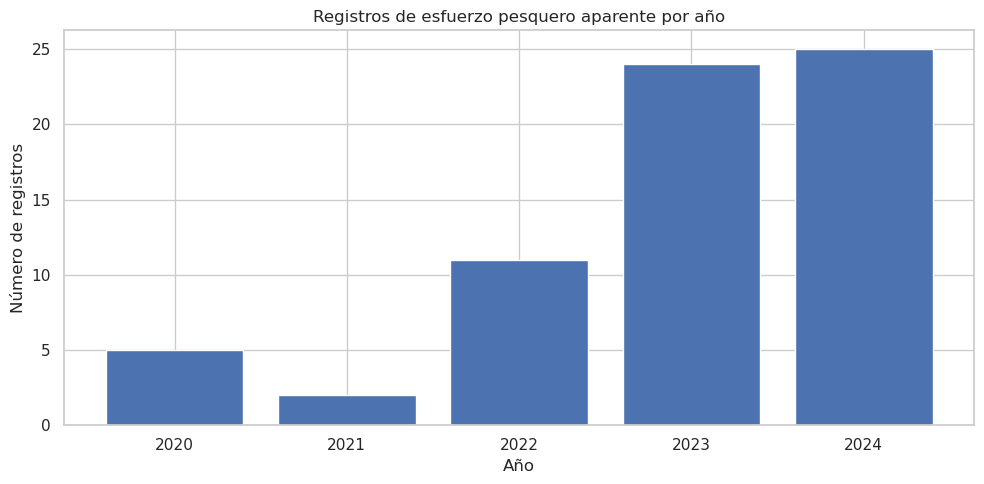

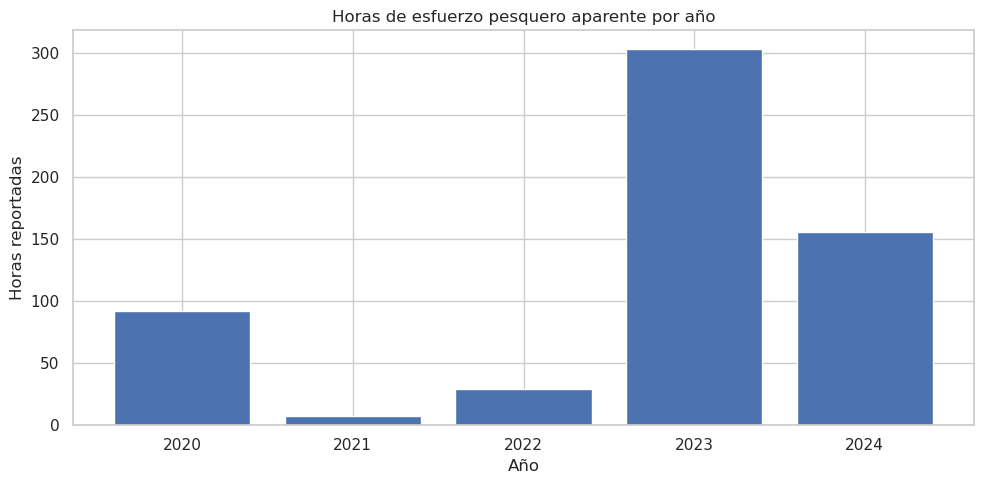

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(resumen_anual["anio"].astype(str), resumen_anual["registros"])
ax1.set_xlabel("Año")
ax1.set_ylabel("Número de registros")
ax1.set_title("Registros de esfuerzo pesquero aparente por año")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(resumen_anual["anio"].astype(str), resumen_anual["horas_aparentes"])
ax.set_xlabel("Año")
ax.set_ylabel("Horas reportadas")
ax.set_title("Horas de esfuerzo pesquero aparente por año")
plt.tight_layout()
plt.show()

## 7. Distribución mensual e interanual

Se calculan dos métricas distintas: cantidad de registros y suma de horas. No deben interpretarse como equivalentes.

In [8]:
resumen_mensual = (
    df.groupby(["anio", "mes"])
      .agg(registros=("date", "size"),
           horas_aparentes=("hours", "sum"))
      .reset_index()
)
display(resumen_mensual.head(15).round(2))

,anio,mes,registros,horas_aparentes
0,2020,4,1,52.05
1,2020,7,1,0.97
2,2020,9,3,39.12
3,2021,4,2,7.45
4,2022,6,1,4.81
5,2022,7,2,2.33
6,2022,8,1,0.49
7,2022,10,2,6.01
8,2022,11,2,2.67
9,2022,12,3,12.88


### 7.1 Mapa de calor: número de registros por mes y año

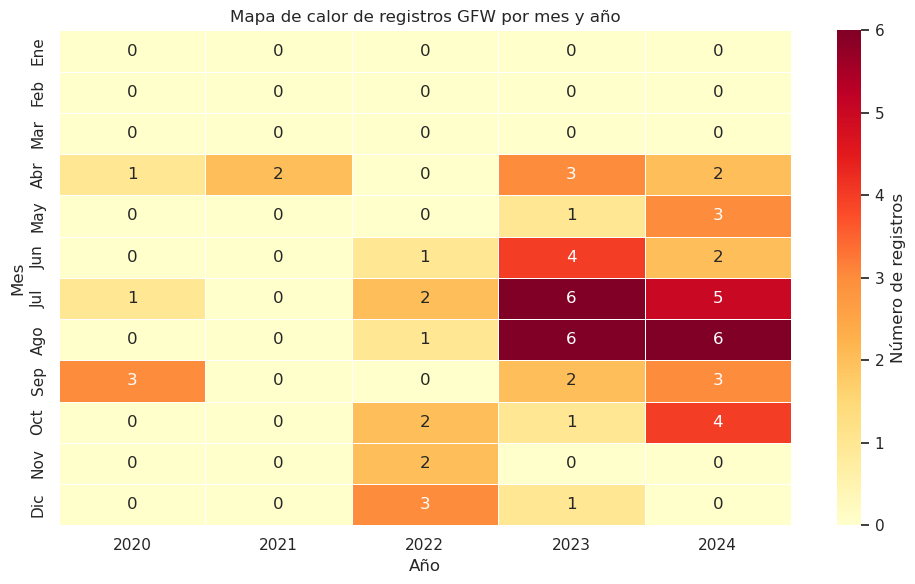

In [9]:
tabla_registros = (
    df.pivot_table(index="mes", columns="anio", values="date",
                   aggfunc="count", fill_value=0)
      .reindex(range(1, 13), fill_value=0)
)
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                 "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
tabla_registros.index = nombres_meses

plt.figure(figsize=(10, 6))
sns.heatmap(tabla_registros, annot=True, fmt="g", cmap="YlOrRd",
            linewidths=0.5, cbar_kws={"label": "Número de registros"})
plt.title("Mapa de calor de registros GFW por mes y año")
plt.xlabel("Año")
plt.ylabel("Mes")
plt.tight_layout()
plt.show()

### 7.2 Mapa de calor: horas reportadas por mes y año

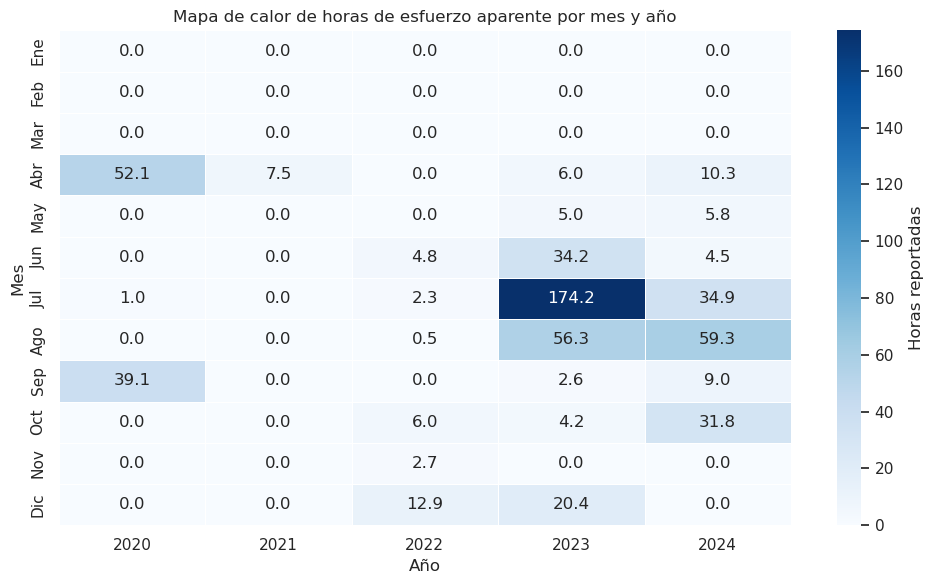

In [10]:
tabla_horas = (
    df.pivot_table(index="mes", columns="anio", values="hours",
                   aggfunc="sum", fill_value=0)
      .reindex(range(1, 13), fill_value=0)
)
tabla_horas.index = nombres_meses

plt.figure(figsize=(10, 6))
sns.heatmap(tabla_horas, annot=True, fmt=".1f", cmap="Blues",
            linewidths=0.5, cbar_kws={"label": "Horas reportadas"})
plt.title("Mapa de calor de horas de esfuerzo aparente por mes y año")
plt.xlabel("Año")
plt.ylabel("Mes")
plt.tight_layout()
plt.show()

## 8. Mapa de Japón y acercamiento cartográfico a Shiretoko

Se utiliza la capa terrestre Natural Earth a escala 1:10m, como en el notebook original, para recuperar el detalle de costa. Se muestran los registros agregados por coordenada y coloreados/tamaneados según las horas acumuladas de esfuerzo aparente.

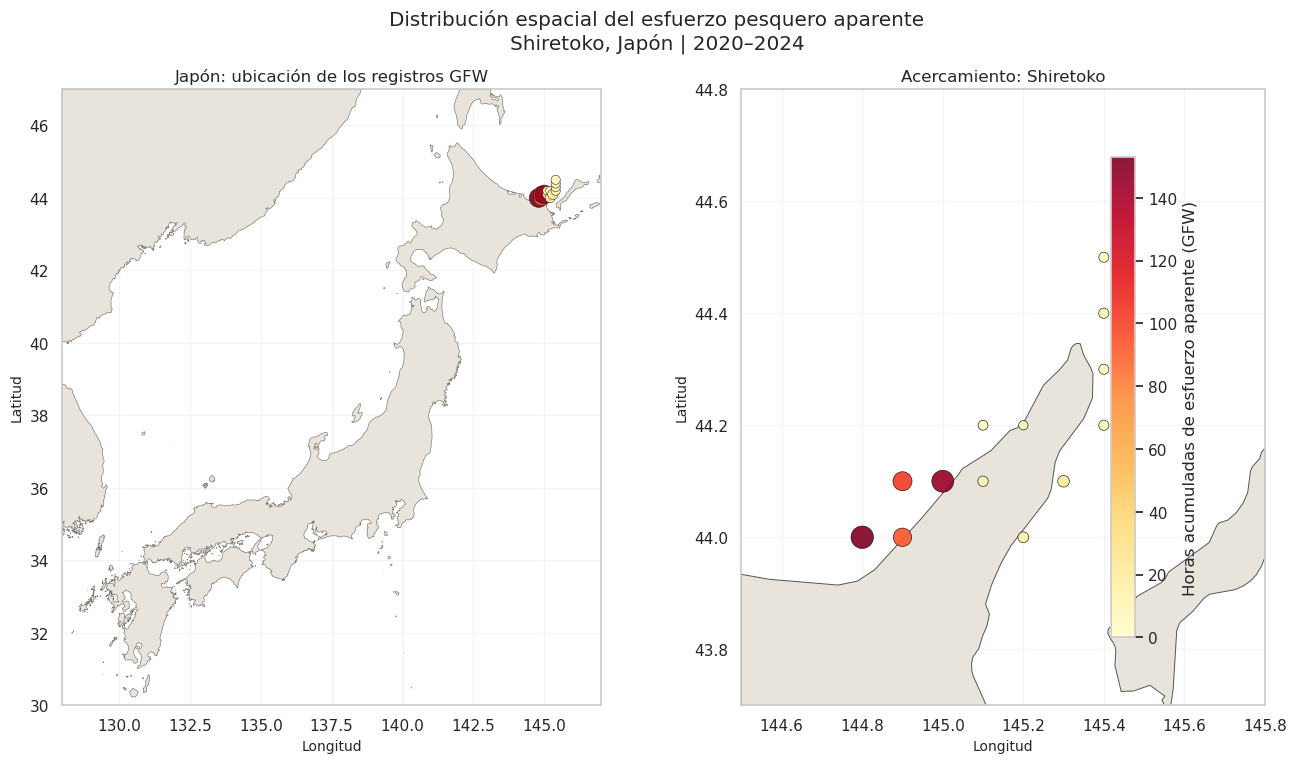

In [11]:
# Cartografía de contexto: Japón y acercamiento a Shiretoko
# Recupera la capa terrestre de Natural Earth a escala 1:10m usada en el notebook original.

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

URL_TIERRA = (
    "https://naciscdn.org/naturalearth/10m/physical/"
    "ne_10m_land.zip"
)
RUTA_TIERRA = DIRECTORIO / "ne_10m_land.zip"

# Descargar una sola vez y conservar el archivo en el repositorio/notebooks
if not RUTA_TIERRA.exists():
    import urllib.request
    urllib.request.urlretrieve(URL_TIERRA, RUTA_TIERRA)

tierra = gpd.read_file(RUTA_TIERRA)

# Natural Earth está en coordenadas geográficas (longitud/latitud).
if tierra.crs is None:
    raise ValueError("La capa Natural Earth no tiene CRS definido.")
tierra = tierra.to_crs("EPSG:4326")

# Ventanas cartográficas
limites_japon = box(128, 30, 147, 47)
limites_shiretoko = box(144.5, 43.7, 145.8, 44.8)

japon_contexto = gpd.clip(tierra, limites_japon)
tierra_shiretoko = gpd.clip(tierra, limites_shiretoko)

# Agregar horas por coordenada para que cada punto represente una ubicación
# y no se sobrepongan múltiples símbolos idénticos.
puntos_gfw = (
    df.groupby(["lon", "lat"], as_index=False)
      .agg(registros=("date", "size"),
           horas_aparentes=("hours", "sum"))
)

max_horas = max(float(puntos_gfw["horas_aparentes"].max()), 1.0)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Panel izquierdo: archipiélago japonés y ubicación de los registros
japon_contexto.plot(
    ax=axes[0], color="#e8e4dc", edgecolor="#77736b",
    linewidth=0.45, zorder=1
)
sc0 = axes[0].scatter(
    puntos_gfw["lon"], puntos_gfw["lat"],
    c=puntos_gfw["horas_aparentes"],
    s=35 + 150 * puntos_gfw["horas_aparentes"] / max_horas,
    cmap="YlOrRd", vmin=0, vmax=max_horas,
    edgecolor="black", linewidth=0.35, alpha=0.9, zorder=3
)
axes[0].set_xlim(128, 147)
axes[0].set_ylim(30, 47)
axes[0].set_title("Japón: ubicación de los registros GFW")
axes[0].set_xlabel("Longitud")
axes[0].set_ylabel("Latitud")
axes[0].grid(alpha=0.2)

# Panel derecho: costa detallada de Shiretoko y puntos de esfuerzo
tierra_shiretoko.plot(
    ax=axes[1], color="#e8e4dc", edgecolor="#555555",
    linewidth=0.7, zorder=1
)
sc1 = axes[1].scatter(
    puntos_gfw["lon"], puntos_gfw["lat"],
    c=puntos_gfw["horas_aparentes"],
    s=40 + 220 * puntos_gfw["horas_aparentes"] / max_horas,
    cmap="YlOrRd", vmin=0, vmax=max_horas,
    edgecolor="black", linewidth=0.45, alpha=0.9, zorder=3
)
axes[1].set_xlim(144.5, 145.8)
axes[1].set_ylim(43.7, 44.8)
axes[1].set_title("Acercamiento: Shiretoko")
axes[1].set_xlabel("Longitud")
axes[1].set_ylabel("Latitud")
axes[1].grid(alpha=0.2)

cbar = fig.colorbar(sc1, ax=axes, shrink=0.78, pad=0.03)
cbar.set_label("Horas acumuladas de esfuerzo aparente (GFW)")
fig.suptitle(
    "Distribución espacial del esfuerzo pesquero aparente\n"
    "Shiretoko, Japón | 2020–2024",
    y=0.98
)
fig.subplots_adjust(top=0.88, wspace=0.22, right=0.88)
plt.show()


## 9. Distribución espacial de los registros

El primer mapa representa cada registro como un punto. El tamaño y color representan horas reportadas. La visualización depende de las coordenadas incluidas en el producto GFW consultado.

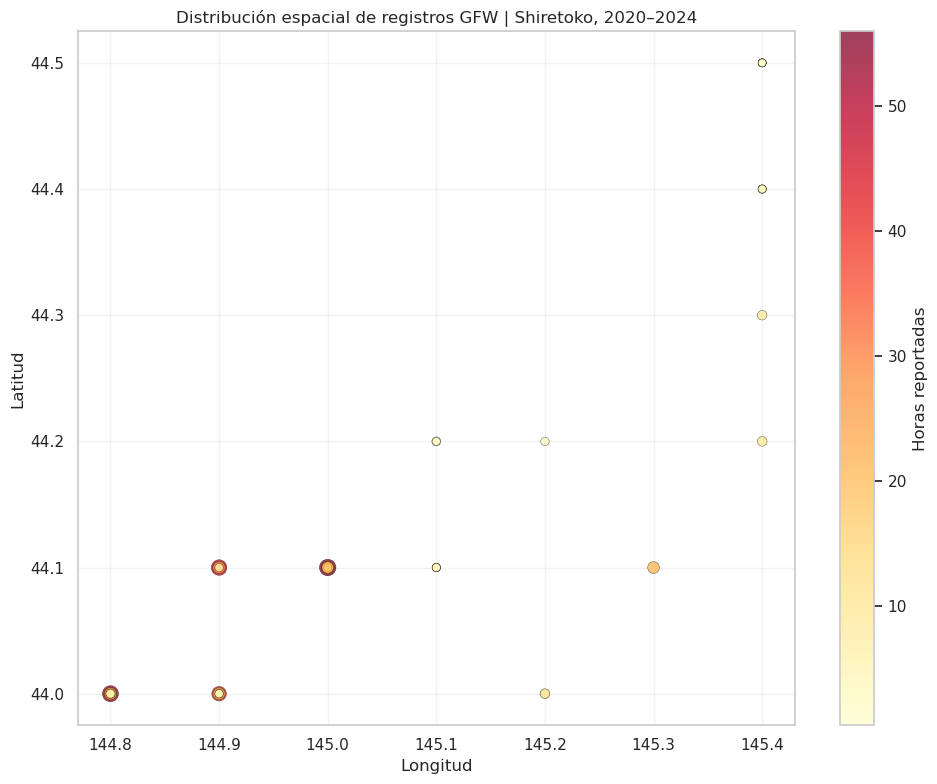

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))
puntos = ax.scatter(
    df["lon"], df["lat"],
    c=df["hours"], s=30 + df["hours"].clip(lower=0) * 2,
    cmap="YlOrRd", alpha=0.75, edgecolor="black", linewidth=0.3
)
plt.colorbar(puntos, ax=ax, label="Horas reportadas")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Distribución espacial de registros GFW | Shiretoko, 2020–2024")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Mapa de concentración espacial

Se agrega el número de registros y las horas por coordenada. Este mapa permite identificar concentraciones de observaciones, pero no representa densidad de captura ni abundancia de peces.

,lat,lon,registros,horas_aparentes,meses_activos,anios_activos
0,44.0,144.8,14,152.98,14,4
4,44.1,145.0,12,144.76,12,3
1,44.0,144.9,9,93.24,9,3
12,44.5,145.4,8,8.69,8,3
11,44.4,145.4,6,9.82,6,4
5,44.1,145.1,5,10.97,5,2
3,44.1,144.9,5,102.79,5,2
2,44.0,145.2,2,14.51,2,2
7,44.2,145.1,2,7.01,2,2
8,44.2,145.2,1,3.43,1,1


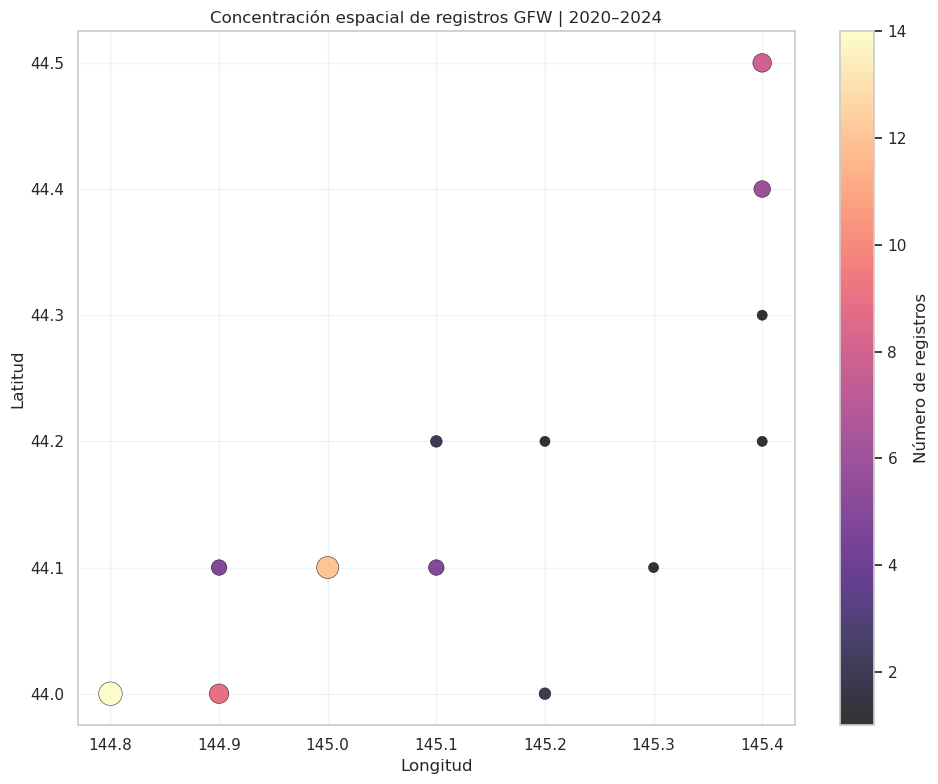

In [13]:
concentracion = (
    df.groupby(["lat", "lon"], as_index=False)
      .agg(registros=("date", "size"),
           horas_aparentes=("hours", "sum"),
           meses_activos=("date", "nunique"),
           anios_activos=("anio", "nunique"))
      .sort_values("registros", ascending=False)
)
display(concentracion.head(10).round(2))

fig, ax = plt.subplots(figsize=(10, 8))
p = ax.scatter(concentracion["lon"], concentracion["lat"],
               c=concentracion["registros"],
               s=35 + concentracion["registros"] * 18,
               cmap="magma", alpha=0.8, edgecolor="black", linewidth=0.4)
plt.colorbar(p, ax=ax, label="Número de registros")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Concentración espacial de registros GFW | 2020–2024")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Mapa espacial de calor por mes

Se generan 12 paneles (uno por mes) usando las coordenadas de los registros. La intensidad representa **cantidad de registros en cada celda del histograma**, no horas ni intensidad de pesca. Se usa una misma escala de color entre meses para facilitar la comparación.

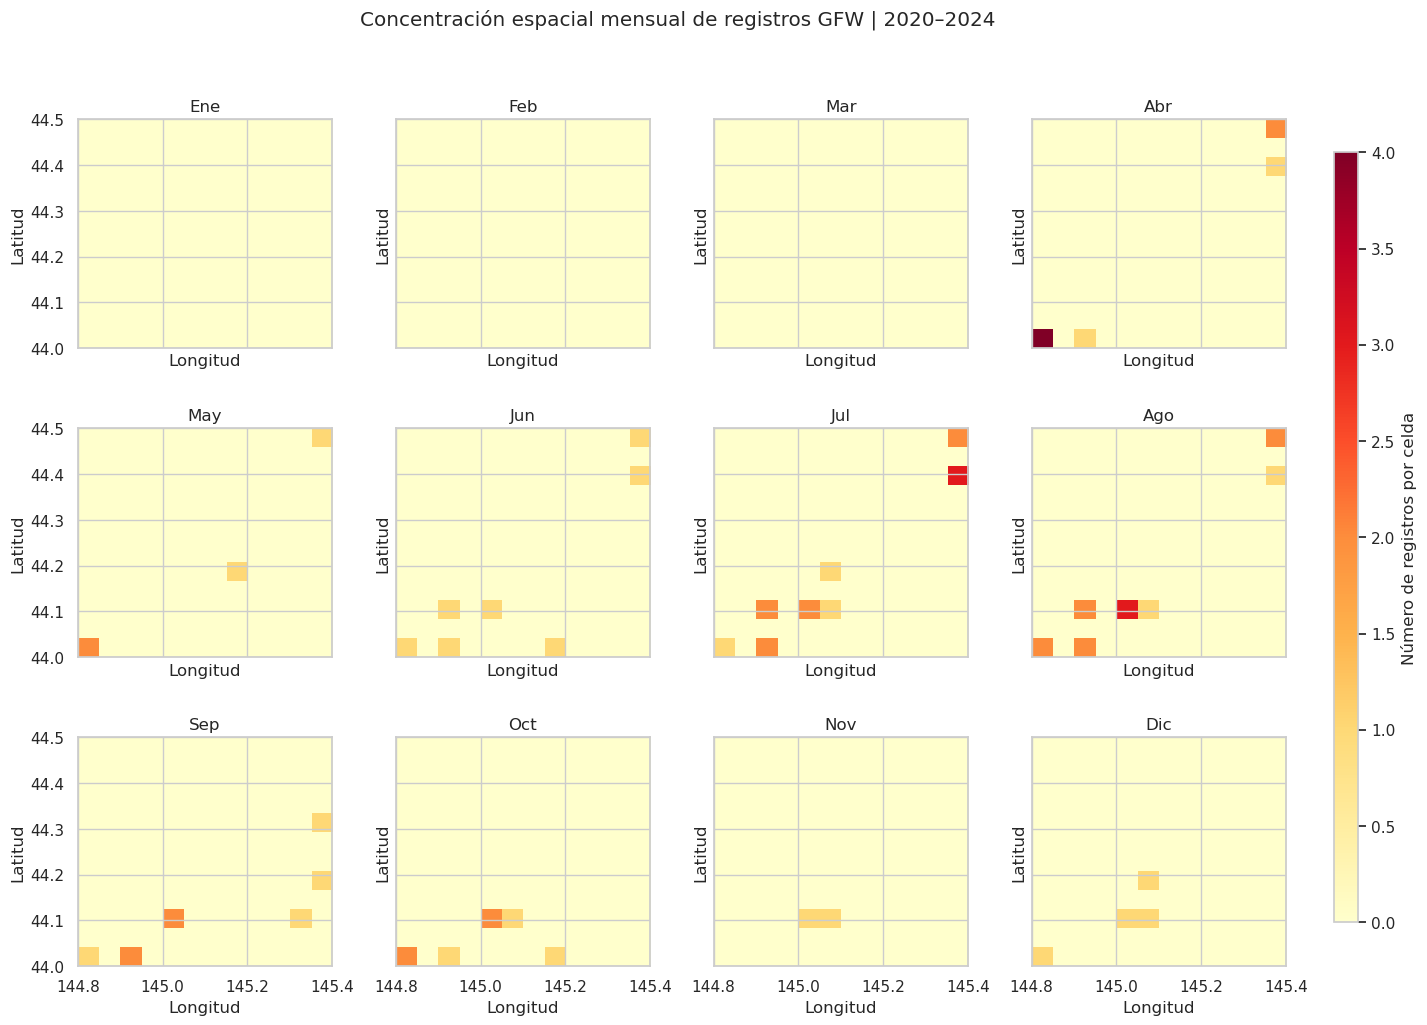

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11), sharex=True, sharey=True)
axes = axes.flatten()

# Límites comunes para comparar los meses
xmin, xmax = df["lon"].min(), df["lon"].max()
ymin, ymax = df["lat"].min(), df["lat"].max()

# Calcular primero los histogramas para compartir la escala
histogramas = []
for mes in range(1, 13):
    subset = df[df["mes"] == mes]
    if len(subset):
        H, xedges, yedges = np.histogram2d(
            subset["lon"], subset["lat"], bins=12,
            range=[[xmin, xmax], [ymin, ymax]]
        )
    else:
        H = np.zeros((12, 12))
    histogramas.append(H.T)

vmax = max((h.max() for h in histogramas), default=1)
vmax = max(vmax, 1)

for mes, ax, H in zip(range(1, 13), axes, histogramas):
    imagen = ax.imshow(
        H, origin="lower", extent=[xmin, xmax, ymin, ymax],
        cmap="YlOrRd", vmin=0, vmax=vmax, aspect="auto"
    )
    ax.set_title(nombres_meses[mes-1])
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")

fig.subplots_adjust(right=0.88, hspace=0.35, wspace=0.25)
cax = fig.add_axes([0.91, 0.15, 0.015, 0.7])
fig.colorbar(imagen, cax=cax, label="Número de registros por celda")
fig.suptitle("Concentración espacial mensual de registros GFW | 2020–2024", y=0.98)
plt.show()

In [15]:
for columna in ["flag", "gear_type", "vessel_type", "dataset"]:
    if columna in df.columns:
        print(f"\nDistribución de {columna}:")
        display(df[columna].fillna("Sin dato").value_counts().head(15).to_frame("registros"))


Distribución de flag:


,registros
flag,
Sin dato,67



Distribución de gear_type:


,registros
gear_type,
Sin dato,67



Distribución de vessel_type:


,registros
vessel_type,
Sin dato,67



Distribución de dataset:


,registros
dataset,
Sin dato,67


## 13. Exportación de resultados

Las tablas se guardan en `datos/procesados/GFW/` para utilizarlas posteriormente en la integración con clorofila-a.

In [16]:
RUTA_SALIDA = DIRECTORIO.parent / "datos" / "procesados" / "GFW"
RUTA_SALIDA.mkdir(parents=True, exist_ok=True)

resumen_anual.to_csv(RUTA_SALIDA / "resumen_anual_GFW.csv", index=False)
resumen_mensual.to_csv(RUTA_SALIDA / "resumen_mensual_GFW.csv", index=False)
concentracion.to_csv(RUTA_SALIDA / "concentracion_espacial_GFW.csv", index=False)
tabla_registros.to_csv(RUTA_SALIDA / "heatmap_registros_mes_anio.csv")

print("Tablas exportadas en:", RUTA_SALIDA)

Tablas exportadas en: /home/jovyan/tutoriales/17-martes/ohwe26-proy2-python/datos/procesados/GFW


## 14. Conclusiones y limitaciones para la siguiente fase

Completar esta sección después de ejecutar el notebook y revisar las figuras.

- ¿Qué años y meses concentran más registros?
- ¿Los meses con más registros también acumulan más horas?
- ¿La actividad se concentra en las mismas coordenadas o cambia entre meses?
- ¿Qué meses tienen pocos o ningún registro? ¿Es ausencia de actividad o ausencia de detección/datos?
- ¿Qué limitaciones impone la resolución LOW y MONTHLY?

**Precauciones:** los registros de GFW no deben tratarse automáticamente como eventos independientes ni como número de viajes. La suma de horas es esfuerzo aparente estimado por el sistema. Los mapas de calor dependen del tamaño de celda elegido. Antes de comparar con clorofila-a habrá que armonizar cobertura espacial, periodo, resolución, sistema de coordenadas y máscara oceánica. La asociación espacial o temporal no demuestra que la clorofila cause la actividad pesquera.